# Preparación de datos: Resultados únicos Saber 11

**Autores:** Erlyn Martinez y Jonatan Esguerra

Este cuadernillo continúa el EDA. Cada paso llama a una función del módulo `src/preparacion.py`, y aquí solo se muestra el antes y el después de cada una.

**Objetivo de modelado:** predecir `PUNT_GLOBAL` (regresión) a partir del colegio, el estudiante y su entorno familiar.

**Flujo:**
1. Limpieza: duplicados, registros válidos y puntajes fuera de rango
2. Variables nuevas: año, edad y residencia en el mismo municipio
3. Codificación de variables categóricas
4. Eliminación de columnas innecesarias
5. Selección del objetivo y de las variables predictoras
6. Partición train/test
7. Imputación y escalado, ajustados solo con train
8. Guardado de los conjuntos finales

## 1. Carga y configuración

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import pandas as pd

from src.graficos import AZUL, NARANJA, barras, configurar_estilo, histograma
from src.preparacion import (
    OBJETIVO, PUNTAJES_AREA, ajustar_escalado, ajustar_imputacion, aplicar_escalado,
    cargar_datos, columnas_constantes, convertir_fecha_nacimiento, corregir_puntajes,
    crear_variables, dividir_train_test, eliminar_columnas_innecesarias,
    eliminar_duplicados, filtrar_objetivo_valido, filtrar_registros_validos,
    guardar_datasets, seleccionar_variables, transformar_categoricas,
)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
configurar_estilo()

df_original = cargar_datos()
print('Dimensiones originales:', df_original.shape)

Dimensiones originales: (36613, 51)


## 2. Duplicados

En el EDA se encontraron filas idénticas en los periodos 2019-4 y 2022-4.

In [2]:
df = eliminar_duplicados(df_original)
print('Antes:', df_original.shape[0], '| Después:', df.shape[0], '| Eliminadas:', df_original.shape[0] - df.shape[0])

Antes: 36613 | Después: 30854 | Eliminadas: 5759


* filas eliminadas: 5.759
* filas restantes: 30.854
* los identificadores `ESTU_CONSECUTIVO` quedan únicos

In [3]:
print('Identificadores repetidos:', df['ESTU_CONSECUTIVO'].duplicated().sum())

Identificadores repetidos: 0


## 3. Registros válidos

Solo se conservan los estudiantes con estado `PUBLICAR`.

In [4]:
print(df['ESTU_ESTADOINVESTIGACION'].value_counts())
df = filtrar_registros_validos(df)
print('Filas después del filtro:', df.shape[0])

ESTU_ESTADOINVESTIGACION
PUBLICAR                                  30806
PRESENTE CON LECTURA TARDIA                  42
VALIDEZ OFICINA JURÍDICA                      5
NO SE COMPROBO IDENTIDAD DEL EXAMINADO        1
Name: count, dtype: int64
Filas después del filtro: 30806


* registros en investigación (lectura tardía, validez jurídica, identidad no comprobada): 48
* esos puntajes no son oficiales, por eso se descartan

## 4. Puntajes fuera de rango

El EDA encontró 13 valores negativos y 5 mayores a 100 en `PUNT_INGLES`. Aquí se revisan todas las pruebas.

In [5]:
fuera = pd.DataFrame({
    'negativos': (df[PUNTAJES_AREA] < 0).sum(),
    'mayores_100': (df[PUNTAJES_AREA] > 100).sum()
})
fuera

,negativos,mayores_100
PUNT_INGLES,13,5
PUNT_MATEMATICAS,0,1
PUNT_SOCIALES_CIUDADANAS,0,0
PUNT_C_NATURALES,0,0
PUNT_LECTURA_CRITICA,0,0


In [6]:
df[df['PUNT_INGLES'] < 0]['PUNT_INGLES'].value_counts()

PUNT_INGLES
-1.0    13
Name: count, dtype: int64

* todos los negativos de inglés valen -1: es un código de "sin dato", no un puntaje
* los valores sobre 100 (inglés hasta 117,29 y una nota de matemáticas de 101) no caben en la escala oficial
* decisión: convertirlos a nulo y rellenarlos más adelante con la mediana de train

In [7]:
antes = df[PUNTAJES_AREA].isna().sum()
df = corregir_puntajes(df)
despues = df[PUNTAJES_AREA].isna().sum()
pd.DataFrame({'nulos_antes': antes, 'nulos_despues': despues})

,nulos_antes,nulos_despues
PUNT_INGLES,0,18
PUNT_MATEMATICAS,0,1
PUNT_SOCIALES_CIUDADANAS,13139,13139
PUNT_C_NATURALES,13139,13139
PUNT_LECTURA_CRITICA,13139,13139


Los nulos de sociales, naturales y lectura (13.139) corresponden a los periodos anteriores a 2014-2, que no tienen puntaje global. Esos no se corrigen aquí, se tratan en la sección 8.

## 5. Variables nuevas

* `ANIO`: año del examen, sale de `PERIODO`
* `EDAD`: años cumplidos al presentar el examen
* `RESIDE_MISMO_MCPIO`: 1 si el estudiante vive en el municipio de su colegio

In [8]:
nacimiento = convertir_fecha_nacimiento(df['ESTU_FECHANACIMIENTO'])
print('Fechas de nacimiento imposibles (año < 1940):', (nacimiento.dt.year < 1940).sum())
print('Año mínimo de nacimiento:', nacimiento.dt.year.min())

Fechas de nacimiento imposibles (año < 1940): 0
Año mínimo de nacimiento: 1942.0


In [9]:
df = crear_variables(df)
df[['PERIODO', 'ANIO', 'EDAD', 'RESIDE_MISMO_MCPIO']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PERIODO,30806.0,20149.89,36.03,20101.0,20122.0,20142.0,20172.0,20224.0
ANIO,30806.0,2014.76,3.54,2010.0,2012.0,2014.0,2017.0,2022.0
EDAD,30697.0,17.58,3.19,12.0,16.0,17.0,18.0,68.0
RESIDE_MISMO_MCPIO,30614.0,0.94,0.24,0.0,1.0,1.0,1.0,1.0


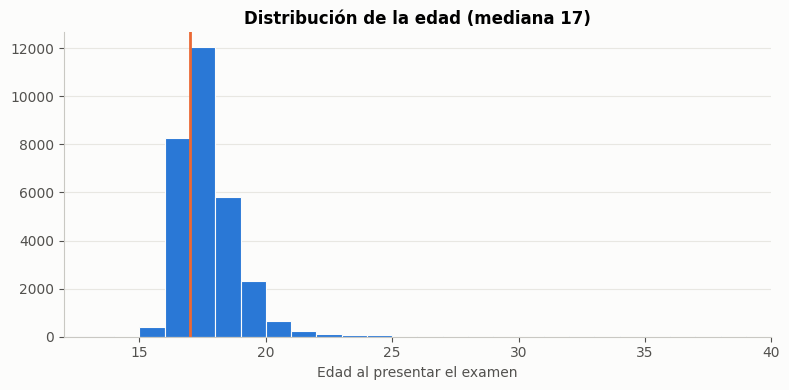

Edades fuera de 12 a 70 (quedan como nulo): 109


In [10]:
edad = df['EDAD'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
histograma(ax, edad, f'Distribución de la edad (mediana {edad.median():.0f})', bins=range(12, 71))
ax.axvline(edad.median(), color=NARANJA, linewidth=2)
ax.set_xlabel('Edad al presentar el examen')
ax.set_xlim(12, 40)
plt.tight_layout()
plt.show()
print('Edades fuera de 12 a 70 (quedan como nulo):', df['EDAD'].isna().sum())

* la mitad de los estudiantes tiene entre 16 y 18 años
* edades fuera de 12 a 70 por fechas erróneas (por ejemplo, año 0009): 109, quedan como nulo

## 6. Codificación de variables categóricas

| Tipo | Variables | Tratamiento |
|---|---|---|
| Ordinal | estrato, educación de madre y padre, cuartos, personas del hogar | número según el orden natural |
| Binaria | naturaleza, zona, bilingüe, sede principal, género, carro, computador, internet, lavadora | 0 / 1 |
| Nominal | carácter, jornada, municipio del colegio | one-hot (municipios con menos de 300 estudiantes en `OTROS`) |

### 6.1 Problema en personas del hogar

A partir de 2017 la encuesta cambió de número exacto a rangos, por eso hay dos formas de responder la misma pregunta.

In [11]:
pd.crosstab(df['ANIO'], df['FAMI_PERSONASHOGAR'].str.contains(' a |o más', na=False)).rename(
    columns={False: 'número exacto', True: 'rango'})

FAMI_PERSONASHOGAR,número exacto,rango
ANIO,,
2010,3270,12
2011,3405,13
2012,3215,11
2013,3062,19
2014,3002,6
2015,3023,3
2016,2883,10
2017,48,2836
2018,0,52


* hasta 2016 casi todo viene como número y desde 2017 como rango
* se unifican en 5 rangos: 1 a 2, 3 a 4, 5 a 6, 7 a 8 y 9 o más

### 6.2 Educación de los padres

Las respuestas "No sabe" y "No aplica" no tienen orden, por eso pasan a nulo y se guarda un indicador `EDUC_*_NO_SABE` para no perder esa información.

In [12]:
print(df['FAMI_EDUCACIONPADRE'].isin(['No sabe', 'No Aplica']).sum(), 'padres con respuesta No sabe / No aplica')
print(df['FAMI_EDUCACIONMADRE'].isin(['No sabe', 'No Aplica']).sum(), 'madres con respuesta No sabe / No aplica')

1328 padres con respuesta No sabe / No aplica
346 madres con respuesta No sabe / No aplica


### 6.3 Aplicar la codificación

In [13]:
columnas_antes = df.shape[1]
df = transformar_categoricas(df)
print('Columnas antes:', columnas_antes, '| después:', df.shape[1])
df.select_dtypes(include=['object', 'string']).columns.tolist()

Columnas antes: 54 | después: 78


['ESTU_TIPODOCUMENTO',
 'ESTU_CONSECUTIVO',
 'COLE_CALENDARIO',
 'COLE_DEPTO_UBICACION',
 'COLE_GENERO',
 'COLE_NOMBRE_ESTABLECIMIENTO',
 'COLE_NOMBRE_SEDE',
 'ESTU_DEPTO_PRESENTACION',
 'ESTU_DEPTO_RESIDE',
 'ESTU_ESTADOINVESTIGACION',
 'ESTU_ESTUDIANTE',
 'ESTU_FECHANACIMIENTO',
 'ESTU_MCPIO_PRESENTACION',
 'ESTU_MCPIO_RESIDE',
 'ESTU_NACIONALIDAD',
 'ESTU_PAIS_RESIDE',
 'ESTU_PRIVADO_LIBERTAD',
 'DESEMP_INGLES']

Las columnas de texto que quedan (nombres, códigos, fecha de nacimiento, desempeño de inglés) se eliminan en el siguiente paso.

In [14]:
df.head(3).T

,0,1,2
PERIODO,20132,20162,20172
ESTU_TIPODOCUMENTO,TI,CC,TI
ESTU_CONSECUTIVO,SB11201320260952,SB11201620253914,SB11201720214776
COLE_BILINGUE,0.0,0.0,0.0
COLE_CALENDARIO,A,A,A
COLE_COD_DANE_ESTABLECIMIENTO,115491000017,115759001887,115759000473
COLE_COD_DANE_SEDE,115491000017,115759001887,115759000473
COLE_COD_DEPTO_UBICACION,15,15,15
COLE_COD_MCPIO_UBICACION,15491,15759,15759
COLE_CODIGO_ICFES,5330.0,64204.0,91454.0


## 7. Eliminación de columnas innecesarias

In [15]:
print('Columnas constantes (un único valor):', columnas_constantes(df))

Columnas constantes (un único valor): ['COLE_COD_DEPTO_UBICACION', 'COLE_DEPTO_UBICACION', 'ESTU_COD_DEPTO_PRESENTACION', 'ESTU_COD_MCPIO_PRESENTACION', 'ESTU_DEPTO_PRESENTACION', 'ESTU_ESTADOINVESTIGACION', 'ESTU_ESTUDIANTE', 'ESTU_MCPIO_PRESENTACION', 'ESTU_PRIVADO_LIBERTAD']


Columnas que se eliminan:

* identificadores y nombres: consecutivo, tipo de documento, nombres y códigos DANE e ICFES
* códigos que repiten el nombre del lugar
* constantes o casi constantes: departamento, calendario, género del colegio y nacionalidad (99,9 % Colombia)
* lugar de residencia, resumido en `RESIDE_MISMO_MCPIO`
* `ESTU_FECHANACIMIENTO` (ya está en `EDAD`) y `DESEMP_INGLES` (es el puntaje de inglés agrupado)

In [16]:
columnas_antes = df.shape[1]
df_limpio = eliminar_columnas_innecesarias(df)
print('Columnas antes:', columnas_antes, '| después:', df_limpio.shape[1])
df_limpio.shape

Columnas antes: 78 | después: 51


(30806, 51)

## 8. Objetivo y variables predictoras

### 8.1 Periodos sin puntaje global

El puntaje global existe solo desde 2014-2. Los periodos anteriores no sirven para entrenar un modelo que predice ese puntaje.

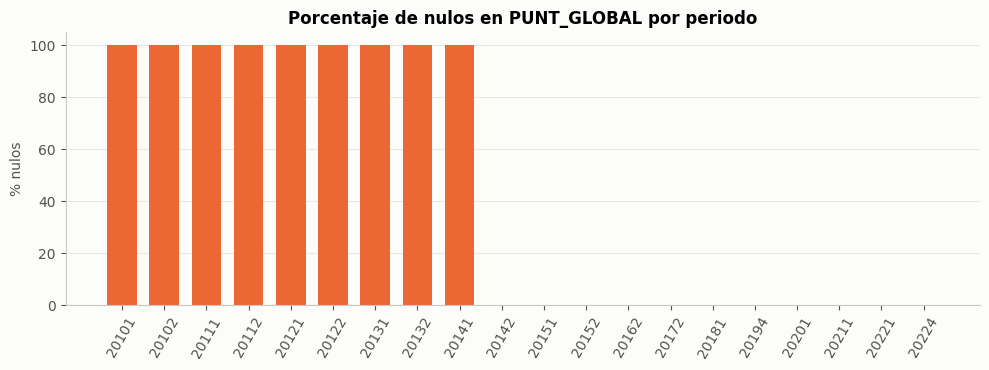

In [17]:
nulos_periodo = df_limpio.groupby('PERIODO')[OBJETIVO].apply(lambda s: s.isna().mean() * 100).round(1)
fig, ax = plt.subplots(figsize=(10, 3.8))
barras(ax, nulos_periodo.index, nulos_periodo.values, 'Porcentaje de nulos en PUNT_GLOBAL por periodo',
       colores=[NARANJA if v > 0 else AZUL for v in nulos_periodo.values], ylabel='% nulos', rotar=60)
plt.tight_layout()
plt.show()

* los 9 periodos anteriores a 2014-2 tienen 100 % de nulos en el objetivo
* se descartan esas 13.139 filas
* el único puntaje global igual a 0 ya salió en el paso 3: era un registro con lectura tardía

In [18]:
df_modelo = filtrar_objetivo_valido(df_limpio)
print('Filas antes:', df_limpio.shape[0], '| después:', df_modelo.shape[0])

Filas antes: 30806 | después: 17667


### 8.2 Puntajes por área y fuga de datos

El puntaje global se calcula a partir de matemáticas, lectura, sociales y naturales. Si esas columnas entran como predictoras, el modelo acierta casi siempre sin aprender nada del contexto del estudiante.

In [19]:
corr_global = df_modelo[PUNTAJES_AREA + [OBJETIVO]].corr()[OBJETIVO].drop(OBJETIVO).round(2)
corr_global

PUNT_INGLES                 0.75
PUNT_MATEMATICAS            0.89
PUNT_SOCIALES_CIUDADANAS    0.89
PUNT_C_NATURALES            0.90
PUNT_LECTURA_CRITICA        0.87
Name: PUNT_GLOBAL, dtype: float64

* las cuatro áreas que componen el global tienen una correlación muy alta con él (0,87 a 0,90) e inglés llega a 0,75
* decisión: se excluyen los cinco puntajes por área y el modelo predice el global solo con colegio, estudiante y familia
* si el objetivo del proyecto cambia, `seleccionar_variables(incluir_puntajes_area=True)` conserva `PUNT_INGLES`, que no entra en el cálculo del global

In [20]:
X, y = seleccionar_variables(df_modelo)
print('X:', X.shape, '| y:', y.shape)
print('Variables predictoras:', X.shape[1])

X: (17667, 44) | y: (17667,)
Variables predictoras: 44


## 9. Partición train / test

80 % para entrenar y 20 % para evaluar, con semilla fija para que sea reproducible.

In [21]:
X_train, X_test, y_train, y_test = dividir_train_test(X, y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print(f'Media del objetivo -> train: {y_train.mean():.1f} | test: {y_test.mean():.1f}')

Train: (14133, 44) | Test: (3534, 44)
Media del objetivo -> train: 270.0 | test: 269.7


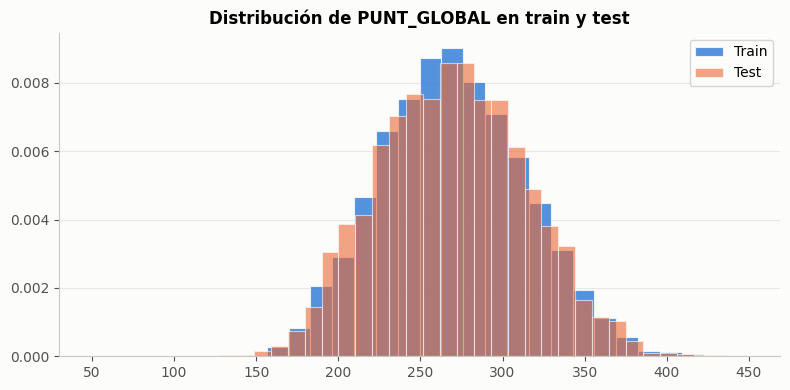

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
histograma(ax, y_train, bins=30, density=True, alpha=0.8, label='Train')
histograma(ax, y_test, color=NARANJA, bins=30, density=True, alpha=0.6, label='Test')
ax.set_title('Distribución de PUNT_GLOBAL en train y test')
ax.legend()
plt.tight_layout()
plt.show()

* ambas particiones tienen la misma forma y un promedio casi igual, así que la separación es representativa

## 10. Imputación de nulos

Los valores de relleno se calculan **solo con train** y se aplican a train y test, para que el test no influya en el entrenamiento.

* variables binarias: moda
* variables numéricas u ordinales: mediana

In [23]:
nulos_train = X_train.isna().sum()
nulos_train[nulos_train > 0].to_frame('nulos_train').assign(
    porcentaje=lambda t: (t['nulos_train'] / len(X_train) * 100).round(2))

,nulos_train,porcentaje
COLE_BILINGUE,622,4.40
EDAD,17,0.12
RESIDE_MISMO_MCPIO,3,0.02
ESTRATO,417,2.95
EDUC_MADRE,474,3.35
EDUC_PADRE,1012,7.16
CUARTOS_HOGAR,172,1.22
PERSONAS_HOGAR,187,1.32
ESTU_FEMENINO,20,0.14
TIENE_AUTOMOVIL,169,1.20


In [24]:
imputacion = ajustar_imputacion(X_train)
pd.Series(imputacion, name='valor de relleno')

COLE_BILINGUE          0.0
EDAD                  17.0
RESIDE_MISMO_MCPIO     1.0
ESTRATO                2.0
EDUC_MADRE             4.0
EDUC_PADRE             3.0
CUARTOS_HOGAR          3.0
PERSONAS_HOGAR         2.0
ESTU_FEMENINO          1.0
TIENE_AUTOMOVIL        0.0
TIENE_COMPUTADOR       1.0
TIENE_INTERNET         0.0
TIENE_LAVADORA         1.0
Name: valor de relleno, dtype: float64

In [25]:
X_train_imp = X_train.fillna(imputacion)
X_test_imp = X_test.fillna(imputacion)
print('Nulos en train:', X_train_imp.isna().sum().sum(), '| Nulos en test:', X_test_imp.isna().sum().sum())

Nulos en train: 0 | Nulos en test: 0


* el mayor porcentaje de nulos está en la educación del padre (7,2 %) y de la madre (3,4 %), por eso se conservan los indicadores `*_NO_SABE`
* después de imputar no quedan nulos en ninguna partición

## 11. Escalado

Se estandarizan (media 0, desviación 1) las variables continuas u ordinales con parámetros de train. Se guardan las dos versiones: sin escalar para modelos de árboles y escalada para regresión lineal, KNN o redes.

In [26]:
escalado = ajustar_escalado(X_train_imp)
print('Columnas escaladas:', list(escalado))
X_train_esc = aplicar_escalado(X_train_imp, escalado)
X_test_esc = aplicar_escalado(X_test_imp, escalado)
pd.DataFrame({
    'media_antes': X_train_imp[list(escalado)].mean(),
    'desv_antes': X_train_imp[list(escalado)].std(),
    'media_despues': X_train_esc[list(escalado)].mean(),
    'desv_despues': X_train_esc[list(escalado)].std()
}).round(2)

Columnas escaladas: ['EDAD', 'ESTRATO', 'EDUC_MADRE', 'EDUC_PADRE', 'CUARTOS_HOGAR', 'PERSONAS_HOGAR', 'ANIO']


,media_antes,desv_antes,media_despues,desv_despues
EDAD,17.34,2.24,0.0,1.0
ESTRATO,1.91,0.70,-0.0,1.0
EDUC_MADRE,3.81,2.24,-0.0,1.0
EDUC_PADRE,3.47,2.22,0.0,1.0
CUARTOS_HOGAR,2.89,0.92,0.0,1.0
PERSONAS_HOGAR,2.40,0.73,0.0,1.0
ANIO,2017.20,2.68,-0.0,1.0


Las variables binarias y las de one-hot no se escalan porque ya están en 0 / 1.

## 12. Guardado

In [27]:
train = X_train_imp.assign(**{OBJETIVO: y_train})
test = X_test_imp.assign(**{OBJETIVO: y_test})
train_esc = X_train_esc.assign(**{OBJETIVO: y_train})
test_esc = X_test_esc.assign(**{OBJETIVO: y_test})

rutas = guardar_datasets(df_limpio, train, test, train_esc, test_esc)
pd.DataFrame({'archivo': [r.relative_to(r.parents[2]).as_posix() for r in rutas],
              'tamaño (KB)': [round(r.stat().st_size / 1024) for r in rutas]})

,archivo,tamaño (KB)
0,data/modificado/saber11_limpio.csv,4516
1,data/entrenamiento/train.csv,1753
2,data/entrenamiento/train_escalado.csv,3235
3,data/test/test.csv,439
4,data/test/test_escalado.csv,809


## 13. Verificación final

In [28]:
pd.Series({
    'filas train': len(train),
    'filas test': len(test),
    'variables predictoras': X_train_imp.shape[1],
    'nulos en train': int(train.isna().sum().sum()),
    'nulos en test': int(test.isna().sum().sum()),
    'columnas de texto': X_train_imp.select_dtypes(include=['object', 'string']).shape[1],
    'columnas constantes': len(columnas_constantes(X_train_imp)),
})

filas train              14133
filas test                3534
variables predictoras       44
nulos en train               0
nulos en test                0
columnas de texto            0
columnas constantes          0
dtype: int64

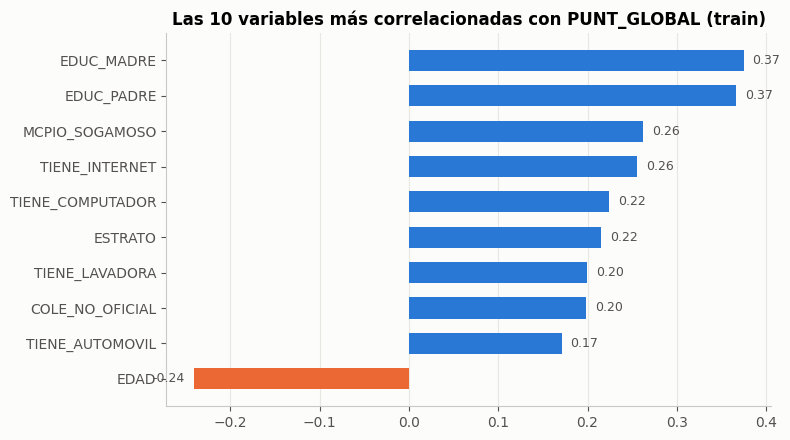

In [29]:
corr = train.corr()[OBJETIVO].drop(OBJETIVO)
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
barras(ax, top.index, top.values, 'Las 10 variables más correlacionadas con PUNT_GLOBAL (train)',
       colores=[AZUL if v > 0 else NARANJA for v in top.values], horizontal=True, anotar=True)
plt.tight_layout()
plt.show()

## 14. Resumen

| Paso | Resultado |
|---|---|
| Filas originales | 36.613 |
| Duplicados eliminados | 5.759 |
| Registros no oficiales eliminados | 48 |
| Puntajes fuera de rango pasados a nulo | 19 (18 en inglés, 1 en matemáticas) |
| Columnas tras la limpieza (incluye puntajes y objetivo) | 51 |
| Periodos sin puntaje global descartados | 9 periodos anteriores a 2014-2 |
| Filas para modelar (desde 2014-2) | 17.667 |
| Train / Test | 14.133 / 3.534 |
| Variables predictoras | 44 |
| Nulos finales | 0 |

**Decisiones principales**

* los cinco puntajes por área quedan fuera de las predictoras para evitar fuga de datos
* imputación y escalado se ajustan solo con train
* personas del hogar se unifican en 5 rangos porque la encuesta cambió de formato en 2017

**Archivos generados:**

* `data/modificado/`: `saber11_limpio.csv`
* `data/entrenamiento/`: `train.csv`, `train_escalado.csv`
* `data/test/`: `test.csv`, `test_escalado.csv`